<a href="https://colab.research.google.com/github/Maryam-Yaqoob/NLP-LAB/blob/main/FA23_BAI_025___Lab07_POS_NER____Maryam_Yaqoob.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 7: POS Tagging & Named Entity Recognition
**NLP Lab 07 – BSAI 7th**

This notebook solves Tasks 1–9 using spaCy.

Setup (run once if needed):
```
pip install spacy matplotlib
python -m spacy download en_core_web_sm
```

In [32]:
!pip install spacy matplotlib
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 45.3 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [33]:
import spacy
from spacy import displacy
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import json

nlp = spacy.load("en_core_web_sm")
print("spaCy version:", spacy.__version__)
print("Pipeline:", nlp.pipe_names)

spaCy version: 3.8.18
Pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


## Task 1: Coarse vs Fine-Grained POS Tags
Sentence: *"The quick brown fox jumped over the lazy dogs near the river."*

In [34]:
sentence1 = "The quick brown fox jumped over the lazy dogs near the river."
doc1 = nlp(sentence1)

# a) Token + coarse POS (.pos_)
print("a) Coarse-grained POS (.pos_)")
print(f"{'TOKEN':<10}{'POS':<8}")
for t in doc1:
    print(f"{t.text:<10}{t.pos_:<8}")

a) Coarse-grained POS (.pos_)
TOKEN     POS     
The       DET     
quick     ADJ     
brown     ADJ     
fox       NOUN    
jumped    VERB    
over      ADP     
the       DET     
lazy      ADJ     
dogs      NOUN    
near      ADP     
the       DET     
river     NOUN    
.         PUNCT   


In [35]:
# b) Token + coarse POS + fine-grained tag (.tag_)
print("b) Token | .pos_ | .tag_")
print(f"{'TOKEN':<10}{'POS':<8}{'TAG':<8}")
for t in doc1:
    print(f"{t.text:<10}{t.pos_:<8}{t.tag_:<8}")

b) Token | .pos_ | .tag_
TOKEN     POS     TAG     
The       DET     DT      
quick     ADJ     JJ      
brown     ADJ     JJ      
fox       NOUN    NN      
jumped    VERB    VBD     
over      ADP     IN      
the       DET     DT      
lazy      ADJ     JJ      
dogs      NOUN    NNS     
near      ADP     IN      
the       DET     DT      
river     NOUN    NN      
.         PUNCT   .       


In [36]:
# c) Human-readable descriptions of every unique .pos_ and .tag_
print("c) Unique .pos_ values")
for p in sorted({t.pos_ for t in doc1}):
    print(f"  {p:<8}-> {spacy.explain(p)}")

print("\n   Unique .tag_ values")
for tg in sorted({t.tag_ for t in doc1}):
    print(f"  {tg:<8}-> {spacy.explain(tg)}")

c) Unique .pos_ values
  ADJ     -> adjective
  ADP     -> adposition
  DET     -> determiner
  NOUN    -> noun
  PUNCT   -> punctuation
  VERB    -> verb

   Unique .tag_ values
  .       -> punctuation mark, sentence closer
  DT      -> determiner
  IN      -> conjunction, subordinating or preposition
  JJ      -> adjective (English), other noun-modifier (Chinese)
  NN      -> noun, singular or mass
  NNS     -> noun, plural
  VBD     -> verb, past tense


In [37]:
# d) Distinct .tag_ values per .pos_, and POS groups with more than one tag
pos_to_tags = defaultdict(set)
for t in doc1:
    pos_to_tags[t.pos_].add(t.tag_)

print("d) Number of distinct .tag_ values per .pos_")
for pos, tags in sorted(pos_to_tags.items()):
    print(f"  {pos:<6}: {len(tags)}  {sorted(tags)}")

print("\nTokens whose .pos_ maps to more than one .tag_ (fine-grained tag adds extra detail):")
for t in doc1:
    if len(pos_to_tags[t.pos_]) > 1:
        print(f"  {t.text:<8} pos={t.pos_:<6} tag={t.tag_:<5} ({spacy.explain(t.tag_)})")

d) Number of distinct .tag_ values per .pos_
  ADJ   : 1  ['JJ']
  ADP   : 1  ['IN']
  DET   : 1  ['DT']
  NOUN  : 2  ['NN', 'NNS']
  PUNCT : 1  ['.']
  VERB  : 1  ['VBD']

Tokens whose .pos_ maps to more than one .tag_ (fine-grained tag adds extra detail):
  fox      pos=NOUN   tag=NN    (noun, singular or mass)
  dogs     pos=NOUN   tag=NNS   (noun, plural)
  river    pos=NOUN   tag=NN    (noun, singular or mass)


## Task 2: Tag Frequency Analysis

In [38]:
para2 = ("Ali bought three fresh apples. He carefully washed them and quickly shared them "
         "with his friends. Everyone happily enjoyed the sweet fruit.")
doc2 = nlp(para2)

# a) .pos_ counts
pos_counts = {}
for t in doc2:
    pos_counts[t.pos_] = pos_counts.get(t.pos_, 0) + 1

# b) .tag_ counts
tag_counts = {}
for t in doc2:
    tag_counts[t.tag_] = tag_counts.get(t.tag_, 0) + 1

# c) Sorted most -> least frequent
pos_sorted = dict(sorted(pos_counts.items(), key=lambda kv: kv[1], reverse=True))
tag_sorted = dict(sorted(tag_counts.items(), key=lambda kv: kv[1], reverse=True))
print("POS counts (sorted):", pos_sorted)
print()
print("TAG counts (sorted):", tag_sorted)

POS counts (sorted): {'PRON': 5, 'VERB': 4, 'NOUN': 3, 'PUNCT': 3, 'ADV': 3, 'ADJ': 2, 'PROPN': 1, 'NUM': 1, 'CCONJ': 1, 'ADP': 1, 'DET': 1}

TAG counts (sorted): {'VBD': 4, '.': 3, 'PRP': 3, 'RB': 3, 'JJ': 2, 'NNS': 2, 'NN': 2, 'NNP': 1, 'CD': 1, 'CC': 1, 'IN': 1, 'PRP$': 1, 'DT': 1}


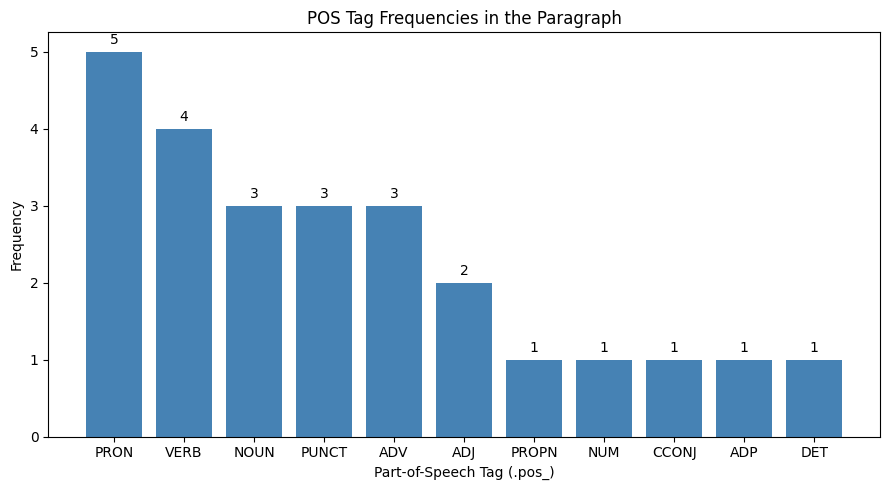

In [39]:
# d) Bar chart of .pos_ frequencies
plt.figure(figsize=(9, 5))
plt.bar(pos_sorted.keys(), pos_sorted.values(), color="steelblue")
plt.xlabel("Part-of-Speech Tag (.pos_)")
plt.ylabel("Frequency")
plt.title("POS Tag Frequencies in the Paragraph")
for i, v in enumerate(pos_sorted.values()):
    plt.text(i, v + 0.1, str(v), ha="center")
plt.tight_layout()
plt.show()

## Task 3: Context-Dependent Tagging

In [40]:
sentences3 = [
    "I will book a flight to Lahore.",
    "She read a good book yesterday.",
    "They run every morning.",
    "We watched the run of the play.",
]
docs3 = [nlp(s) for s in sentences3]

# a) "book"
print("a) Word: 'book'")
for i, d in enumerate(docs3, 1):
    for t in d:
        if t.text.lower() == "book":
            print(f"  Sentence {i}: '{d.text}' -> pos_={t.pos_}, tag_={t.tag_} ({spacy.explain(t.tag_)})")

# b) "run"
print("\nb) Word: 'run'")
for i, d in enumerate(docs3, 1):
    for t in d:
        if t.text.lower() == "run":
            print(f"  Sentence {i}: '{d.text}' -> pos_={t.pos_}, tag_={t.tag_} ({spacy.explain(t.tag_)})")

a) Word: 'book'
  Sentence 1: 'I will book a flight to Lahore.' -> pos_=VERB, tag_=VB (verb, base form)
  Sentence 2: 'She read a good book yesterday.' -> pos_=NOUN, tag_=NN (noun, singular or mass)

b) Word: 'run'
  Sentence 3: 'They run every morning.' -> pos_=VERB, tag_=VBP (verb, non-3rd person singular present)
  Sentence 4: 'We watched the run of the play.' -> pos_=NOUN, tag_=NN (noun, singular or mass)


In [41]:
# c) Reusable function
def compare_word(word, sentences):
    """Return [(sentence_index, pos_, tag_), ...] for every occurrence of `word`."""
    results = []
    for idx, s in enumerate(sentences):
        for tok in nlp(s):
            if tok.text.lower() == word.lower():
                results.append((idx, tok.pos_, tok.tag_))
    return results

print("book:", compare_word("book", sentences3))
print("run :", compare_word("run", sentences3))

book: [(0, 'VERB', 'VB'), (1, 'NOUN', 'NN')]
run : [(2, 'VERB', 'VBP'), (3, 'NOUN', 'NN')]


In [42]:
# d) Two more ambiguous words with two sentences each
play_sents  = ["The children play in the park every evening.",
               "We went to see a play at the theatre."]
watch_sents = ["I always watch cricket matches on weekends.",
               "He bought a new watch from the market."]

print("play :", compare_word("play", play_sents))
print("watch:", compare_word("watch", watch_sents))

# Optional: pretty print
for w, ss in [("play", play_sents), ("watch", watch_sents)]:
    print(f"\n'{w}'")
    for idx, pos, tag in compare_word(w, ss):
        print(f"  sentence {idx}: {ss[idx]!r} -> {pos}, {tag}")

play : [(0, 'VERB', 'VBP'), (1, 'NOUN', 'NN')]
watch: [(0, 'VERB', 'VBP'), (1, 'NOUN', 'NN')]

'play'
  sentence 0: 'The children play in the park every evening.' -> VERB, VBP
  sentence 1: 'We went to see a play at the theatre.' -> NOUN, NN

'watch'
  sentence 0: 'I always watch cricket matches on weekends.' -> VERB, VBP
  sentence 1: 'He bought a new watch from the market.' -> NOUN, NN


## Task 4: Filtering Noise Tokens

In [43]:
messy = " Hello!!! The price is $45.50 ... (really?)\n\n Is it worth it? xyz123 @@ "
doc4 = nlp(messy)

# a) Raw tokens with .pos_
print("a) Raw tokens:")
for i, t in enumerate(doc4):
    print(f"{i:>2}  {t.text!r:<12} {t.pos_}")

a) Raw tokens:
 0  ' '          SPACE
 1  'Hello'      INTJ
 2  '!'          PUNCT
 3  '!'          PUNCT
 4  '!'          PUNCT
 5  'The'        DET
 6  'price'      NOUN
 7  'is'         AUX
 8  '$'          SYM
 9  '45.50'      NUM
10  '...'        PUNCT
11  '('          PUNCT
12  'really'     ADV
13  '?'          PUNCT
14  ')'          PUNCT
15  '\n\n '      SPACE
16  'Is'         AUX
17  'it'         PRON
18  'worth'      ADJ
19  'it'         PRON
20  '?'          PUNCT
21  'xyz123'     PROPN
22  '@@'         PROPN


In [44]:
# b) Remove SPACE, PUNCT, X
noise = {"SPACE", "PUNCT", "X"}
cleaned = [t for t in doc4 if t.pos_ not in noise]
print("b) Cleaned tokens:", [t.text for t in cleaned])

# c) How many removed, and what %
removed = len(doc4) - len(cleaned)
pct = removed / len(doc4) * 100
print(f"\nc) Original tokens: {len(doc4)}")
print(f"   Removed tokens : {removed}")
print(f"   Percentage     : {pct:.2f}%")

b) Cleaned tokens: ['Hello', 'The', 'price', 'is', '$', '45.50', 'really', 'Is', 'it', 'worth', 'it', 'xyz123', '@@']

c) Original tokens: 23
   Removed tokens : 10
   Percentage     : 43.48%


In [45]:
# d) Reusable function
def clean_pos(text, remove=("SPACE", "PUNCT", "X")):
    """Return [(token_text, pos_), ...] with the given POS tags removed."""
    return [(t.text, t.pos_) for t in nlp(text) if t.pos_ not in remove]

test_text = "  Wow!!!  The   car costs $9,999 ... (cheap?)  qwe456 ## ~~ is it good??  \n\n"
print("Raw   :", [(t.text, t.pos_) for t in nlp(test_text)])
print("Clean :", clean_pos(test_text))
print("Clean (keep PUNCT):", clean_pos(test_text, remove=("SPACE", "X")))

Raw   : [('  ', 'SPACE'), ('Wow', 'INTJ'), ('!', 'PUNCT'), ('!', 'PUNCT'), ('!', 'PUNCT'), (' ', 'SPACE'), ('The', 'DET'), ('  ', 'SPACE'), ('car', 'NOUN'), ('costs', 'VERB'), ('$', 'SYM'), ('9,999', 'NUM'), ('...', 'PUNCT'), ('(', 'PUNCT'), ('cheap', 'ADJ'), ('?', 'PUNCT'), (')', 'PUNCT'), (' ', 'SPACE'), ('qwe456', 'VERB'), ('#', 'SYM'), ('#', 'NOUN'), ('~~', 'NUM'), ('is', 'AUX'), ('it', 'PRON'), ('good', 'ADJ'), ('?', 'PUNCT'), ('?', 'PUNCT'), (' \n\n', 'SPACE')]
Clean : [('Wow', 'INTJ'), ('The', 'DET'), ('car', 'NOUN'), ('costs', 'VERB'), ('$', 'SYM'), ('9,999', 'NUM'), ('cheap', 'ADJ'), ('qwe456', 'VERB'), ('#', 'SYM'), ('#', 'NOUN'), ('~~', 'NUM'), ('is', 'AUX'), ('it', 'PRON'), ('good', 'ADJ')]
Clean (keep PUNCT): [('Wow', 'INTJ'), ('!', 'PUNCT'), ('!', 'PUNCT'), ('!', 'PUNCT'), ('The', 'DET'), ('car', 'NOUN'), ('costs', 'VERB'), ('$', 'SYM'), ('9,999', 'NUM'), ('...', 'PUNCT'), ('(', 'PUNCT'), ('cheap', 'ADJ'), ('?', 'PUNCT'), (')', 'PUNCT'), ('qwe456', 'VERB'), ('#', 'SYM'), 

## Task 5: Extracting Specific Parts of Speech

In [46]:
text5 = ("Fatima quickly opened the old wooden door and slowly walked into the dark room. "
         "She carefully placed a small lamp on the heavy table.")
doc5 = nlp(text5)

# a) Nouns (NOUN and PROPN)
nouns = [t.text for t in doc5 if t.pos_ in ("NOUN", "PROPN")]
print("a) Nouns:", nouns)

# b) Verbs with lemmas
print("\nb) Verbs and lemmas:")
for t in doc5:
    if t.pos_ == "VERB":
        print(f"  {t.text:<10} -> {t.lemma_}")

a) Nouns: ['Fatima', 'door', 'room', 'lamp', 'table']

b) Verbs and lemmas:
  opened     -> open
  walked     -> walk
  placed     -> place


In [47]:
# c) Adjective-noun pairs (adjective directly precedes noun, checked by token indices)
pairs = []
for i, t in enumerate(doc5[:-1]):
    nxt = doc5[i + 1]
    if t.pos_ == "ADJ" and nxt.pos_ in ("NOUN", "PROPN") and nxt.i == t.i + 1:
        pairs.append(f"{t.text} {nxt.text}")
print("c) Adjective-noun pairs:", pairs)

c) Adjective-noun pairs: ['wooden door', 'dark room', 'small lamp', 'heavy table']


In [48]:
# d) Summary table
counts = Counter(t.pos_ for t in doc5)
print("d) Summary")
print("-" * 24)
print(f"{'Category':<12}{'Count':>6}")
print("-" * 24)
print(f"{'Nouns':<12}{counts['NOUN'] + counts['PROPN']:>6}")
print(f"{'Verbs':<12}{counts['VERB']:>6}")
print(f"{'Adjectives':<12}{counts['ADJ']:>6}")
print(f"{'Adverbs':<12}{counts['ADV']:>6}")
print("-" * 24)

d) Summary
------------------------
Category     Count
------------------------
Nouns            5
Verbs            3
Adjectives       5
Adverbs          3
------------------------


## Task 6: Basic Named Entity Recognition

In [49]:
text6 = ("Imran Khan visited Google headquarters in California on March 3, 2019, and discussed "
         "a $2 million investment for Pakistan. Later, Microsoft and Amazon announced new offices in Lahore.")
doc6 = nlp(text6)

# a) Entities with positions
print("a) Entities")
print(f"{'TEXT':<20}{'LABEL':<10}{'START':>6}{'END':>6}")
for ent in doc6.ents:
    print(f"{ent.text:<20}{ent.label_:<10}{ent.start_char:>6}{ent.end_char:>6}")

# b) Meaning of each unique label
print("\nb) Label meanings")
for lab in sorted({e.label_ for e in doc6.ents}):
    print(f"  {lab:<10}-> {spacy.explain(lab)}")

a) Entities
TEXT                LABEL      START   END
Khan                PERSON         6    10
Google              ORG           19    25
California          GPE           42    52
March 3, 2019       DATE          56    69
$2 million          MONEY         87    97
Pakistan            GPE          113   121
Microsoft           ORG          130   139
Amazon              ORG          144   150
Lahore              GPE          176   182

b) Label meanings
  DATE      -> Absolute or relative dates or periods
  GPE       -> Countries, cities, states
  MONEY     -> Monetary values, including unit
  ORG       -> Companies, agencies, institutions, etc.
  PERSON    -> People, including fictional


In [50]:
# c) Group by label
grouped = defaultdict(list)
for ent in doc6.ents:
    grouped[ent.label_].append(ent.text)
print("c) Entities grouped by label:")
print(dict(grouped))

# d) Counts + label with highest count
label_counts = Counter(e.label_ for e in doc6.ents)
print("\nd) Counts per label:", dict(label_counts))
top_label, top_n = label_counts.most_common(1)[0]
print(f"   Most frequent label: {top_label} ({top_n})")

c) Entities grouped by label:
{'PERSON': ['Khan'], 'ORG': ['Google', 'Microsoft', 'Amazon'], 'GPE': ['California', 'Pakistan', 'Lahore'], 'DATE': ['March 3, 2019'], 'MONEY': ['$2 million']}

d) Counts per label: {'PERSON': 1, 'ORG': 3, 'GPE': 3, 'DATE': 1, 'MONEY': 1}
   Most frequent label: ORG (3)


## Task 7: Visualizing Entities with displaCy

In [51]:
text7 = ("Apple opened a new store in Karachi in June 2023. Tim Cook said the company plans to "
         "invest 500 million dollars across Asia by 2025.")
doc7 = nlp(text7)

# a) Render all entities, save to entities.html
html_all = displacy.render(doc7, style="ent", page=True, jupyter=False)
with open("entities.html", "w", encoding="utf-8") as f:
    f.write(html_all)
print("Saved entities.html")
displacy.render(doc7, style="ent", jupyter=True)

Saved entities.html


In [52]:
# b) Only ORG and GPE
options_b = {"ents": ["ORG", "GPE"]}
displacy.render(doc7, style="ent", options=options_b, jupyter=True)

In [53]:
# c) Custom colors: ORG orange, GPE light green
options_c = {"ents": ["ORG", "GPE"],
             "colors": {"ORG": "orange", "GPE": "lightgreen"}}
displacy.render(doc7, style="ent", options=options_c, jupyter=True)

html_c = displacy.render(doc7, style="ent", options=options_c, page=True, jupyter=False)
with open("entities_custom.html", "w", encoding="utf-8") as f:
    f.write(html_c)
print("Saved entities_custom.html")

Saved entities_custom.html


In [54]:
# d) Dependency visualization for the FIRST sentence only
first_sent = list(doc7.sents)[0]
print("First sentence:", first_sent.text)
html_dep = displacy.render(first_sent, style="dep", page=True, jupyter=False)
with open("dependency.html", "w", encoding="utf-8") as f:
    f.write(html_dep)
print("Saved dependency.html")
displacy.render(first_sent, style="dep", jupyter=True)

First sentence: Apple opened a new store in Karachi in June 2023.
Saved dependency.html


## Task 8: Extending the Model with EntityRuler

In [55]:
text8 = ("Dr. Zainab works at LabTech Solutions and uses the Python library NumPy and the framework "
         "TensorFlow. Her colleague Abbas prefers PyTorch and Pandas.")

# a) Plain pretrained model
doc8 = nlp(text8)
print("a) Plain model entities:")
for e in doc8.ents:
    print(f"  {e.text:<20}{e.label_}")

tech_terms = ["NumPy", "TensorFlow", "PyTorch", "Pandas"]
found = {e.text: e.label_ for e in doc8.ents}
print()
for term in tech_terms:
    print(f"  {term:<12}-> {found.get(term, 'MISSED (not detected)')}")

a) Plain model entities:
  Zainab              PERSON
  LabTech Solutions   ORG
  Abbas               PERSON
  PyTorch             PERSON
  Pandas              PERSON

  NumPy       -> MISSED (not detected)
  TensorFlow  -> MISSED (not detected)
  PyTorch     -> PERSON
  Pandas      -> PERSON


In [56]:
# b) Create EntityRuler with TECH label
tech_patterns = [
    {"label": "TECH", "pattern": "NumPy"},                          # string pattern
    {"label": "TECH", "pattern": "TensorFlow"},
    {"label": "TECH", "pattern": [{"LOWER": "pytorch"}]},           # token-based pattern
    {"label": "TECH", "pattern": [{"LOWER": "pandas"}]},
]

nlp_b = spacy.load("en_core_web_sm")
ruler = nlp_b.add_pipe("entity_ruler", before="ner")
ruler.add_patterns(tech_patterns)
print("Pipeline:", nlp_b.pipe_names)

# c) Reprocess
doc8b = nlp_b(text8)
print("\nc) Entities with EntityRuler:")
for e in doc8b.ents:
    print(f"  {e.text:<20}{e.label_}")
print("\nAll four tech terms labelled TECH:",
      all(any(e.text == t and e.label_ == "TECH" for e in doc8b.ents) for t in tech_terms))

Pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'entity_ruler', 'ner']

c) Entities with EntityRuler:
  Zainab              PERSON
  LabTech Solutions   ORG
  NumPy               TECH
  TensorFlow          TECH
  Abbas               PERSON
  PyTorch             TECH
  Pandas              TECH

All four tech terms labelled TECH: True


In [57]:
# d) Experiment: ruler position (before / after ner) and overwrite_ents
def build(position, overwrite):
    n = spacy.load("en_core_web_sm")
    r = n.add_pipe("entity_ruler", config={"overwrite_ents": overwrite}, **{position: "ner"})
    r.add_patterns(tech_patterns)
    return n

for position in ("before", "after"):
    for overwrite in (False, True):
        n = build(position, overwrite)
        d = n(text8)
        print(f"ruler {position:<6} ner | overwrite_ents={overwrite}")
        print("   pipeline:", n.pipe_names)
        print("   entities:", [(e.text, e.label_) for e in d.ents])
        print()

ruler before ner | overwrite_ents=False
   pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'entity_ruler', 'ner']
   entities: [('Zainab', 'PERSON'), ('LabTech Solutions', 'ORG'), ('NumPy', 'TECH'), ('TensorFlow', 'TECH'), ('Abbas', 'PERSON'), ('PyTorch', 'TECH'), ('Pandas', 'TECH')]

ruler before ner | overwrite_ents=True
   pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'entity_ruler', 'ner']
   entities: [('Zainab', 'PERSON'), ('LabTech Solutions', 'ORG'), ('NumPy', 'TECH'), ('TensorFlow', 'TECH'), ('Abbas', 'PERSON'), ('PyTorch', 'TECH'), ('Pandas', 'TECH')]

ruler after  ner | overwrite_ents=False
   pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner', 'entity_ruler']
   entities: [('Zainab', 'PERSON'), ('LabTech Solutions', 'ORG'), ('NumPy', 'TECH'), ('TensorFlow', 'TECH'), ('Abbas', 'PERSON'), ('PyTorch', 'PERSON'), ('Pandas', 'PERSON')]

ruler after  ner | overwrite_ents=True
   pipeline: ['tok2

**Observations**
- `before="ner"`: the ruler sets the TECH entities first, and the statistical NER respects them and works around them. Results are stable.
- `after="ner"` with `overwrite_ents=False`: if the NER already labelled a tech term (e.g. as ORG/PERSON), the ruler will **not** replace it, so some terms may stay mislabelled.
- `after="ner"` with `overwrite_ents=True`: the ruler replaces conflicting NER entities, so all four terms become TECH.

## Task 9: Complete Pipeline: From Raw Text to Structured Information

In [58]:
text9 = ("Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket "
         "from Texas next month. Investors in London and Tokyo reacted quickly, and Tesla shares rose by 4%.")

# a) Cleaning function
def clean_tokens(text, nlp_model=nlp, remove=("SPACE", "PUNCT", "X")):
    """Raw text -> list of dicts with token, pos_, tag_ (noise removed)."""
    return [{"token": t.text, "pos": t.pos_, "tag": t.tag_}
            for t in nlp_model(text) if t.pos_ not in remove]

for row in clean_tokens(text9):
    print(row)

{'token': 'Elon', 'pos': 'PROPN', 'tag': 'NNP'}
{'token': 'Musk', 'pos': 'PROPN', 'tag': 'NNP'}
{'token': 'the', 'pos': 'DET', 'tag': 'DT'}
{'token': 'CEO', 'pos': 'NOUN', 'tag': 'NN'}
{'token': 'of', 'pos': 'ADP', 'tag': 'IN'}
{'token': 'Tesla', 'pos': 'PROPN', 'tag': 'NNP'}
{'token': 'announced', 'pos': 'VERB', 'tag': 'VBN'}
{'token': 'on', 'pos': 'ADP', 'tag': 'IN'}
{'token': 'Tuesday', 'pos': 'PROPN', 'tag': 'NNP'}
{'token': 'that', 'pos': 'SCONJ', 'tag': 'IN'}
{'token': 'SpaceX', 'pos': 'PROPN', 'tag': 'NNP'}
{'token': 'will', 'pos': 'AUX', 'tag': 'MD'}
{'token': 'launch', 'pos': 'VERB', 'tag': 'VB'}
{'token': 'a', 'pos': 'DET', 'tag': 'DT'}
{'token': 'Falcon', 'pos': 'PROPN', 'tag': 'NNP'}
{'token': 'rocket', 'pos': 'NOUN', 'tag': 'NN'}
{'token': 'from', 'pos': 'ADP', 'tag': 'IN'}
{'token': 'Texas', 'pos': 'PROPN', 'tag': 'NNP'}
{'token': 'next', 'pos': 'ADJ', 'tag': 'JJ'}
{'token': 'month', 'pos': 'NOUN', 'tag': 'NN'}
{'token': 'Investors', 'pos': 'NOUN', 'tag': 'NNS'}
{'token':

In [59]:
# b) EntityRuler with PRODUCT label
nlp9 = spacy.load("en_core_web_sm")
ruler9 = nlp9.add_pipe("entity_ruler", before="ner")
ruler9.add_patterns([
    {"label": "PRODUCT", "pattern": "Falcon"},
    {"label": "PRODUCT", "pattern": "Tesla shares"},
])
doc9 = nlp9(text9)

print("Final entities (model + ruler):")
for e in doc9.ents:
    print(f"  {e.text:<15}{e.label_:<10}{spacy.explain(e.label_)}")

Final entities (model + ruler):
  Elon Musk      PERSON    People, including fictional
  Tesla          ORG       Companies, agencies, institutions, etc.
  Tuesday        DATE      Absolute or relative dates or periods
  SpaceX         PERSON    People, including fictional
  Falcon         PRODUCT   Objects, vehicles, foods, etc. (not services)
  Texas          GPE       Countries, cities, states
  next month     DATE      Absolute or relative dates or periods
  London         GPE       Countries, cities, states
  Tokyo          GPE       Countries, cities, states
  Tesla shares   PRODUCT   Objects, vehicles, foods, etc. (not services)
  4%             PERCENT   Percentage, including "%"


In [60]:
# c) Structured output -> output.json
tokens_out = clean_tokens(text9, nlp_model=nlp9)
entities_out = [{"text": e.text, "label": e.label_, "start": e.start_char, "end": e.end_char}
                for e in doc9.ents]
pos_counts_out = dict(Counter(t["pos"] for t in tokens_out))

output = {"tokens": tokens_out, "entities": entities_out, "pos_counts": pos_counts_out}
with open("output.json", "w", encoding="utf-8") as f:
    json.dump(output, f, indent=2, ensure_ascii=False)

print("Saved output.json")
print("pos_counts:", pos_counts_out)
print("entities  :", entities_out)

Saved output.json
pos_counts: {'PROPN': 10, 'DET': 2, 'NOUN': 6, 'ADP': 5, 'VERB': 4, 'SCONJ': 1, 'AUX': 1, 'ADJ': 1, 'CCONJ': 2, 'ADV': 1, 'NUM': 1}
entities  : [{'text': 'Elon Musk', 'label': 'PERSON', 'start': 0, 'end': 9}, {'text': 'Tesla', 'label': 'ORG', 'start': 22, 'end': 27}, {'text': 'Tuesday', 'label': 'DATE', 'start': 42, 'end': 49}, {'text': 'SpaceX', 'label': 'PERSON', 'start': 55, 'end': 61}, {'text': 'Falcon', 'label': 'PRODUCT', 'start': 76, 'end': 82}, {'text': 'Texas', 'label': 'GPE', 'start': 95, 'end': 100}, {'text': 'next month', 'label': 'DATE', 'start': 101, 'end': 111}, {'text': 'London', 'label': 'GPE', 'start': 126, 'end': 132}, {'text': 'Tokyo', 'label': 'GPE', 'start': 137, 'end': 142}, {'text': 'Tesla shares', 'label': 'PRODUCT', 'start': 164, 'end': 176}, {'text': '4%', 'label': 'PERCENT', 'start': 185, 'end': 187}]


In [61]:
# d) displaCy with custom colors + entity/sentence loop
colors9 = {"PERSON": "#ffd54f", "ORG": "orange", "GPE": "lightgreen", "PRODUCT": "#90caf9"}
options9 = {"ents": list(colors9.keys()), "colors": colors9}
displacy.render(doc9, style="ent", options=options9, jupyter=True)

html9 = displacy.render(doc9, style="ent", options=options9, page=True, jupyter=False)
with open("final_entities.html", "w", encoding="utf-8") as f:
    f.write(html9)

print("\nEntity -> source sentence")
for e in doc9.ents:
    print(f"  [{e.label_}] {e.text!r}  <-  {e.sent.text!r}")


Entity -> source sentence
  [PERSON] 'Elon Musk'  <-  'Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.'
  [ORG] 'Tesla'  <-  'Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.'
  [DATE] 'Tuesday'  <-  'Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.'
  [PERSON] 'SpaceX'  <-  'Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.'
  [PRODUCT] 'Falcon'  <-  'Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.'
  [GPE] 'Texas'  <-  'Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.'
  [DATE] 'next month'  <-  'Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next mont